<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/PCA/wine_pca_dimensionality_reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA Project: Shrink 13 Measurements into 2 Without Losing the Story

**Goal:** a laboratory measured **13 chemical properties** of 178 wines made from **three different grape cultivars**. 13 dimensions are impossible to picture. We will use **Principal Component Analysis (PCA)** to squash the data down to 2 or 3 numbers per wine, keep most of the information, and see whether the three cultivars **separate on a simple 2D map**.

**What is PCA?** It finds new axes, called **principal components**, that are combinations of the original columns:

- **PC1** is the direction along which the data **varies the most**.
- **PC2** is the next direction with the most variation that is **perpendicular** (uncorrelated) to PC1.
- And so on. Keeping only the first few components compresses the data while keeping most of its variation.

PCA is **unsupervised** (it never looks at the labels), so it is a close cousin of K-Means from your last project. It is used for **visualization, compression, removing noise, speeding up models** and for decorrelating features (you used it in the Naive Bayes digits project).

**What you will learn**

- Why PCA **needs scaling** (and what breaks without it).
- How PCA works under the hood: build it **from scratch** with a covariance matrix and eigenvectors.
- How to read **explained variance** and decide how many components to keep.
- How to read **loadings** (what each component means) and draw a **biplot**.
- How PCA affects a **classifier**, **reconstruction error** and **clustering**.

**Dataset:** the Wine recognition data set from the UCI repository, bundled with scikit-learn (`load_wine`), so there is **nothing to download or upload**: 178 wines, 13 chemical measurements, and the cultivar (0, 1 or 2). The last cell can save it as a CSV file.

**Steps:** 1) Load, 2) Explore, 3) Why scaling matters, 4) PCA from scratch, 5) How many components?, 6) The 2D map, 7) What do the components mean?, 8) PCA before a classifier, 9) Reconstruction and odd wines, 10) PCA before clustering, 11) Transform a new wine.

Run the cells from top to bottom (Shift + Enter).

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data                      # 13 measurements per wine
y = wine.target                    # the cultivar: 0, 1 or 2 (PCA will NOT see this)
df = X.copy()
df['cultivar'] = y

print('Rows and columns:', X.shape)
print('Missing values:', int(X.isna().sum().sum()))
df.head()

Rows and columns: (178, 13)
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Each row is one wine. The 13 columns are chemical measurements (alcohol, flavanoids, colour intensity, proline and so on). `cultivar` tells us the grape type, and we keep it **only to check the result at the end**: PCA is never allowed to use it.

## Step 2: Explore the data

Wines per cultivar:
target
0    59
1    71
2    48

                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00


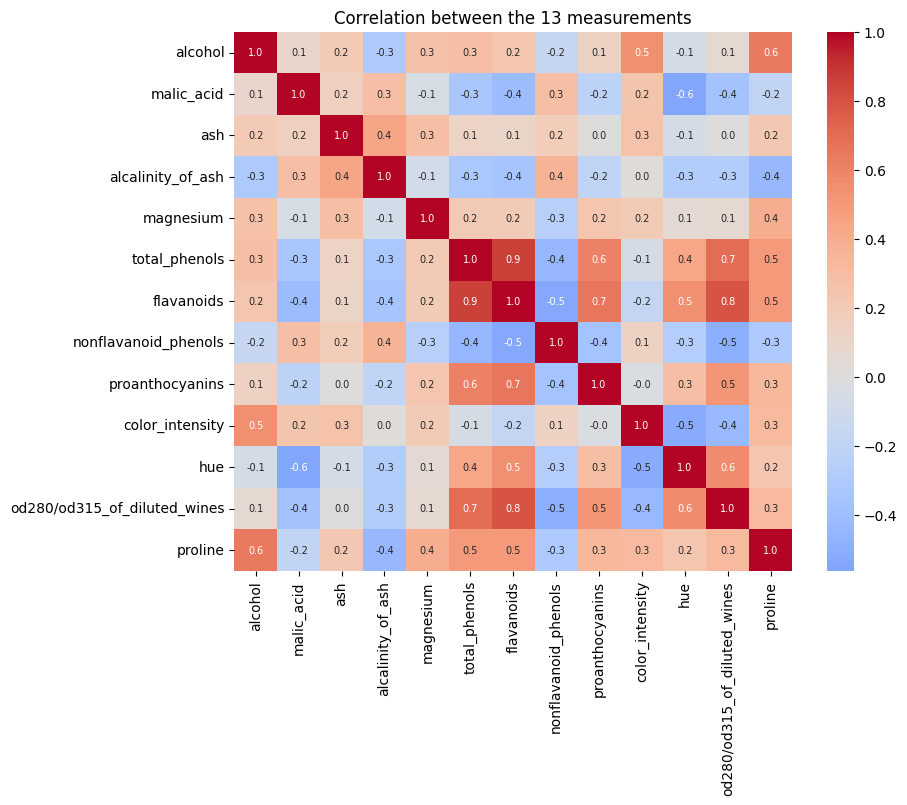

In [2]:
print('Wines per cultivar:')
print(y.value_counts().sort_index().to_string())
print()
desc = X.describe().T[['mean', 'std', 'min', 'max']].round(2)
print(desc.to_string())

plt.figure(figsize=(9, 7))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation between the 13 measurements')
plt.show()

**What to notice:**
- The columns live on **very different scales**: `proline` is in the hundreds or thousands, while `hue` is around 1 and `nonflavanoid_phenols` around 0.4. This matters a lot for PCA (next step).
- Many columns are **correlated** (for example `flavanoids`, `total_phenols` and `od280/od315_of_diluted_wines` move together). That is exactly when PCA works well: correlated columns carry **overlapping information**, so a few components can capture most of it.

## Step 3: Why scaling matters

PCA looks for directions of **maximum variance**. A column measured in large numbers has a huge variance just because of its **units**, so it would hijack the first component. Let us see it: PCA on the raw data against PCA on standardized data (mean 0, spread 1 for each column).

Variance explained by PC1, raw data   : 0.998
Variance explained by PC1, scaled data: 0.362

Features that make up PC1 on RAW data (absolute weights):
proline              1.000
magnesium            0.018
alcalinity_of_ash    0.005


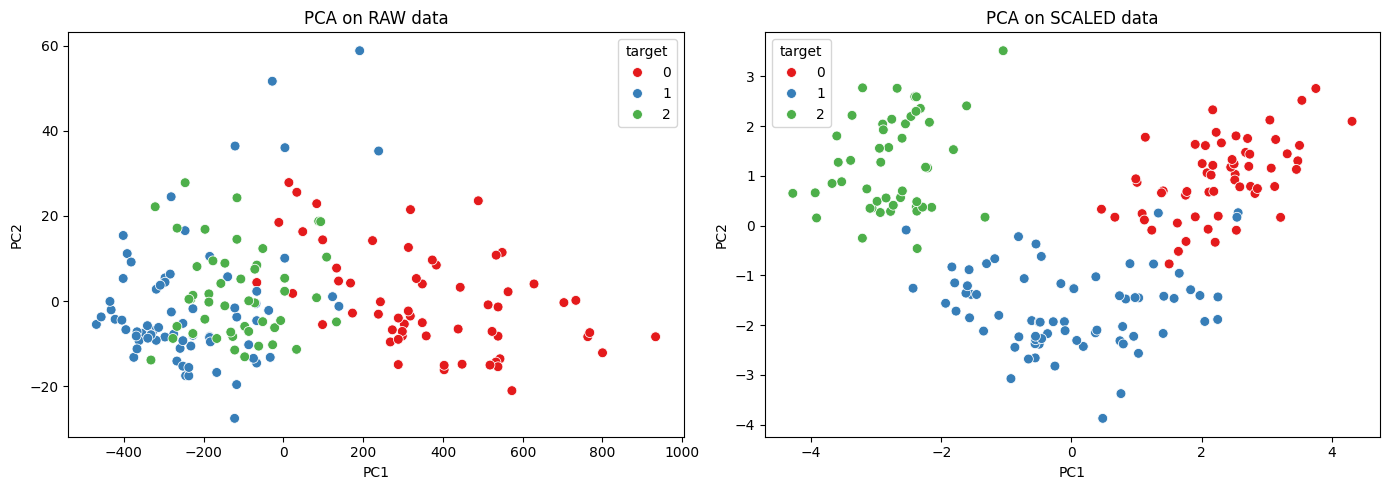

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(X)          # scaled version: every column has mean 0 and std 1

pca_raw = PCA().fit(X)
pca_scaled = PCA().fit(Xs)

print('Variance explained by PC1, raw data   :', round(pca_raw.explained_variance_ratio_[0], 3))
print('Variance explained by PC1, scaled data:', round(pca_scaled.explained_variance_ratio_[0], 3))

top_raw = pd.Series(np.abs(pca_raw.components_[0]), index=X.columns).sort_values(ascending=False)
print()
print('Features that make up PC1 on RAW data (absolute weights):')
print(top_raw.head(3).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, Z, title in [(axes[0], pca_raw.transform(X), 'PCA on RAW data'),
                     (axes[1], pca_scaled.transform(Xs), 'PCA on SCALED data')]:
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette='Set1', s=50, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

**What to notice:** on the raw data, PC1 is made almost entirely of **one column** (`proline`, the one with the biggest numbers) and swallows nearly all of the variance. It is basically a plot of proline, not of "wine in general". After scaling, **every** measurement gets a fair vote and the picture changes. **Rule: standardize before PCA** (unless all your columns already share the same units and scale).

## Step 4: PCA from scratch

PCA is just linear algebra. In four steps:

1. Standardize the data (done: `Xs`).
2. Compute the **covariance matrix** (how every pair of columns varies together).
3. Compute its **eigenvectors** (the directions, i.e. the principal components) and **eigenvalues** (how much variance each direction holds).
4. Sort by eigenvalue (largest first) and **project** the data onto the top directions.

In [4]:
cov = np.cov(Xs, rowvar=False)                       # step 2: 13 x 13 covariance matrix
eigvals, eigvecs = np.linalg.eigh(cov)               # step 3: eigenvalues and eigenvectors
order = np.argsort(eigvals)[::-1]                    # step 4: biggest variance first
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

my_ratio = eigvals / eigvals.sum()
my_scores = Xs @ eigvecs[:, :2]                      # project every wine onto PC1 and PC2

sk = PCA(n_components=2).fit(Xs)
sk_scores = sk.transform(Xs)

print('Our explained-variance ratios (first 4):', my_ratio[:4].round(4))
print('scikit-learn                  (first 4):', pca_scaled.explained_variance_ratio_[:4].round(4))
print()
print('Same variance ratios        :', np.allclose(my_ratio, pca_scaled.explained_variance_ratio_))
print('Same components (ignoring sign):', np.allclose(np.abs(eigvecs[:, :2].T), np.abs(sk.components_)))
print('Same 2D coordinates (ignoring sign):', np.allclose(np.abs(my_scores), np.abs(sk_scores)))

Our explained-variance ratios (first 4): [0.362  0.1921 0.1112 0.0707]
scikit-learn                  (first 4): [0.362  0.1921 0.1112 0.0707]

Same variance ratios        : True
Same components (ignoring sign): True
Same 2D coordinates (ignoring sign): True


**What to notice:** our 8 lines match scikit-learn. The only difference is that an eigenvector can point in either direction, so a component may come out with its **sign flipped** (that is why we compare absolute values). A flipped sign just mirrors the picture and changes nothing important.

(scikit-learn actually uses a numerically safer method called SVD, but it gives the same answer.)

## Step 5: How many components should we keep?

Every component holds a share of the total variance (its **explained variance ratio**). A **scree plot** shows them in order, and the **cumulative** curve shows how much we keep in total as we add components.

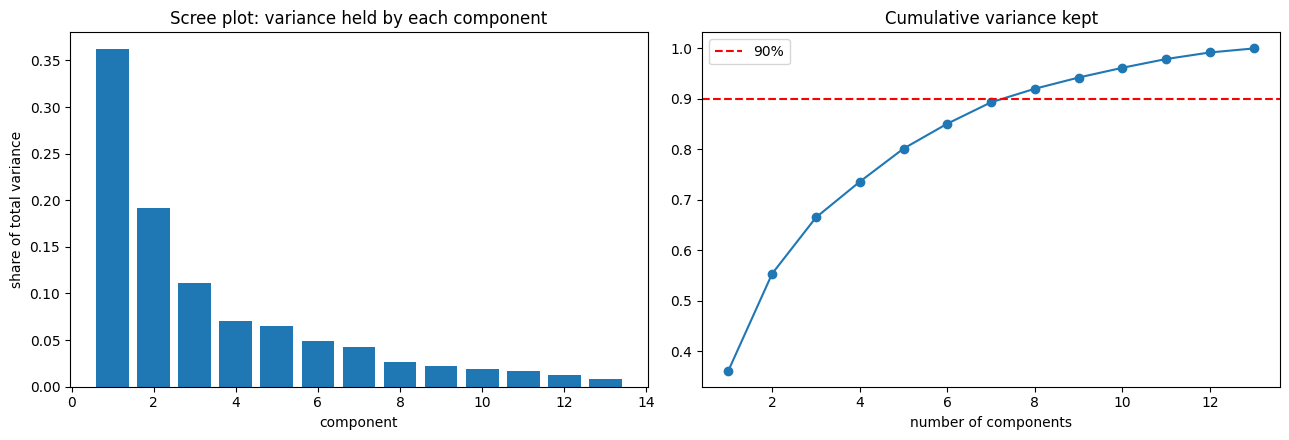

 component  variance share  cumulative
         1           0.362       0.362
         2           0.192       0.554
         3           0.111       0.665
         4           0.071       0.736
         5           0.066       0.802
         6           0.049       0.851
         7           0.042       0.893
         8           0.027       0.920

Components needed to keep 80% of the variance: 5
Components needed to keep 90% of the variance: 8
Components needed to keep 95% of the variance: 10


In [5]:
ratio = pca_scaled.explained_variance_ratio_
cum = np.cumsum(ratio)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, 14), ratio)
axes[0].set_title('Scree plot: variance held by each component')
axes[0].set_xlabel('component')
axes[0].set_ylabel('share of total variance')
axes[1].plot(range(1, 14), cum, marker='o')
axes[1].axhline(0.9, color='red', linestyle='--', label='90%')
axes[1].set_title('Cumulative variance kept')
axes[1].set_xlabel('number of components')
axes[1].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({'component': range(1, 14), 'variance share': ratio, 'cumulative': cum}).round(3).head(8).to_string(index=False))
print()
for target in (0.80, 0.90, 0.95):
    print(f'Components needed to keep {target:.0%} of the variance: {int(np.searchsorted(cum, target) + 1)}')

**How to read this:** the bars fall steadily rather than dropping off a cliff. In a real run, the first two components hold about 55% of the variance, five hold about 80%, eight hold about 90% and ten hold about 95%. So this data can be compressed, but only moderately, because its 13 columns are only partly correlated. Common rules for choosing: keep enough components to reach a target such as **90% or 95%** of the variance; look for the **elbow** in the scree plot; or pick the number that gives the best score in the model you care about (Step 8). For a **plot**, you simply need 2 (or 3).

## Step 6: The 2D map of the wines

We now reduce 13 dimensions to 2. For comparison, we also draw two of the original columns directly.

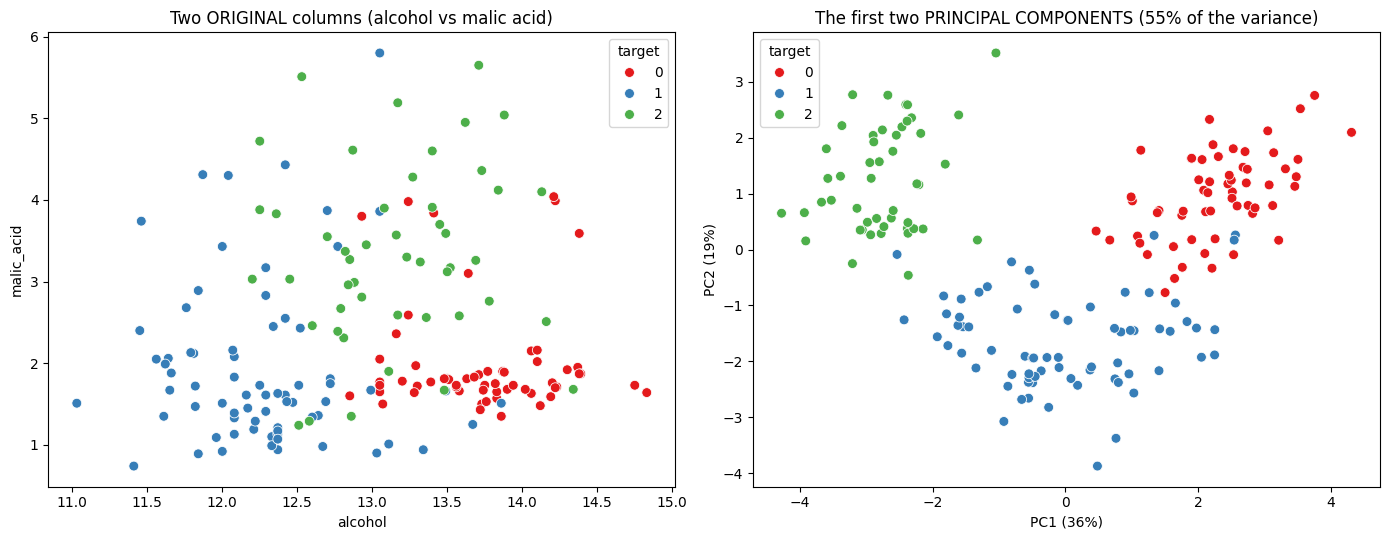

In [6]:
pca2 = PCA(n_components=2).fit(Xs)
Z = pca2.transform(Xs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=X['alcohol'], y=X['malic_acid'], hue=y, palette='Set1', s=50, ax=axes[0])
axes[0].set_title('Two ORIGINAL columns (alcohol vs malic acid)')
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette='Set1', s=50, ax=axes[1])
axes[1].set_title(f'The first two PRINCIPAL COMPONENTS ({pca2.explained_variance_ratio_.sum():.0%} of the variance)')
axes[1].set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.0%})')
axes[1].set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.0%})')
plt.tight_layout()
plt.show()

**What to notice:** the colours (cultivars) were **not** given to PCA, yet on the right-hand plot the three groups form three **distinct clouds with only a little overlap between neighbours**. The two original columns on the left overlap far more. PCA found the directions where the cultivars differ, simply because those directions carry a lot of variance.

One caution: PCA only maximizes variance, not class separation. Here the two happen to line up well, but that is not guaranteed in general.

## Step 7: What do the components mean?

Each component is a **weighted mix of the 13 original columns**. The weights are called **loadings**. A big positive or negative loading means that column strongly influences the component.

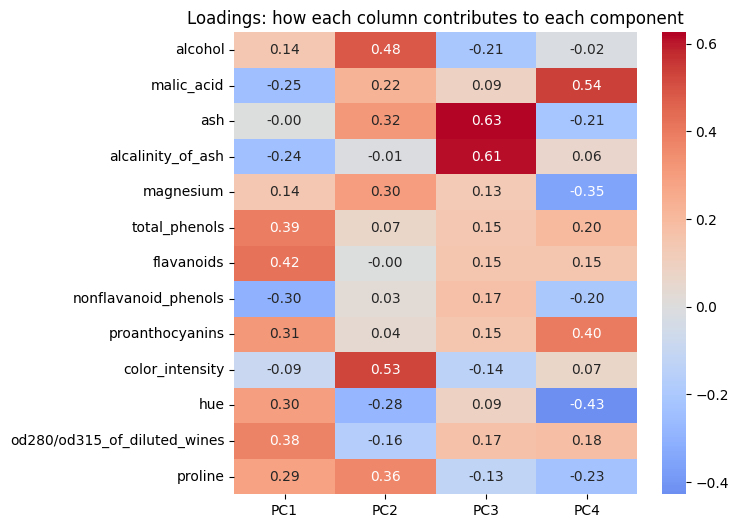

PC1 is driven mostly by: flavanoids (+0.42), total_phenols (+0.39), od280/od315_of_diluted_wines (+0.38), proanthocyanins (+0.31)
PC2 is driven mostly by: color_intensity (+0.53), alcohol (+0.48), proline (+0.36), ash (+0.32)


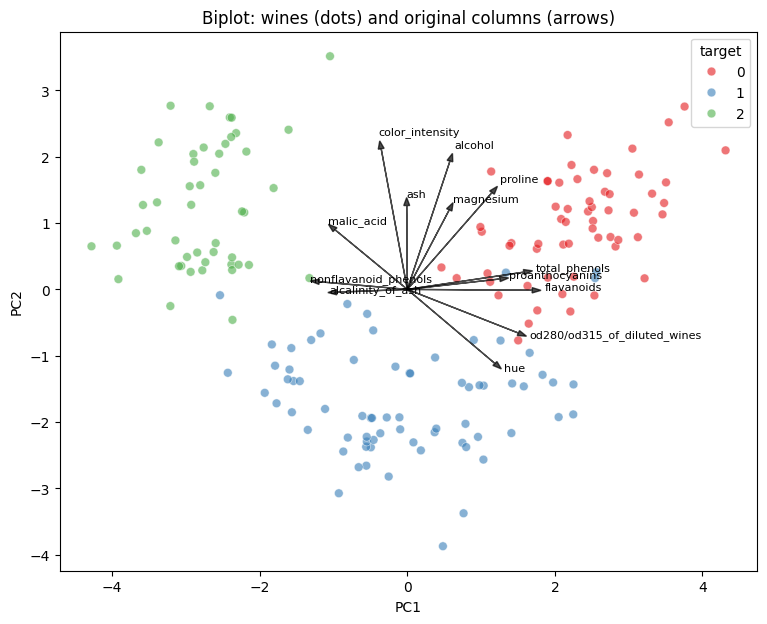

In [7]:
loadings = pd.DataFrame(pca_scaled.components_[:4].T, index=X.columns, columns=['PC1', 'PC2', 'PC3', 'PC4'])

plt.figure(figsize=(6.5, 6))
sns.heatmap(loadings, cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Loadings: how each column contributes to each component')
plt.show()

for pc in ['PC1', 'PC2']:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, 'is driven mostly by:', ', '.join(f'{c} ({loadings.loc[c, pc]:+.2f})' for c in top))

# biplot: the wines plus an arrow for every original column
plt.figure(figsize=(9, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette='Set1', s=40, alpha=0.6)
scale = 4.0
for name, (a, b) in zip(X.columns, pca2.components_.T):
    plt.arrow(0, 0, a * scale, b * scale, color='black', alpha=0.7, head_width=0.08)
    plt.text(a * scale * 1.1, b * scale * 1.1, name, fontsize=8)
plt.title('Biplot: wines (dots) and original columns (arrows)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

**How to read this:** in the heatmap, look for the dark red and dark blue cells in each column to see what that component "is about". In the biplot, an **arrow** points in the direction where that column's value increases; wines lying in the arrow's direction have a high value for it, and arrows pointing the same way are **positively correlated**. In a real run, PC1 is driven mostly by `flavanoids`, `total_phenols` and `od280/od315_of_diluted_wines` (all phenol-related, so you could call it a "phenolic content" axis), while PC2 is driven mostly by `color_intensity`, `alcohol` and `proline`. You decide the name; the computer only gives the numbers.

## Step 8: PCA before a classifier

Does compressing the data hurt a model? We train logistic regression using only the first `n` components, for `n` from 1 to 13, and compare with using all 13 original columns. We do **everything inside a pipeline**, so the scaler and the PCA learn only from the training part of each cross-validation fold.

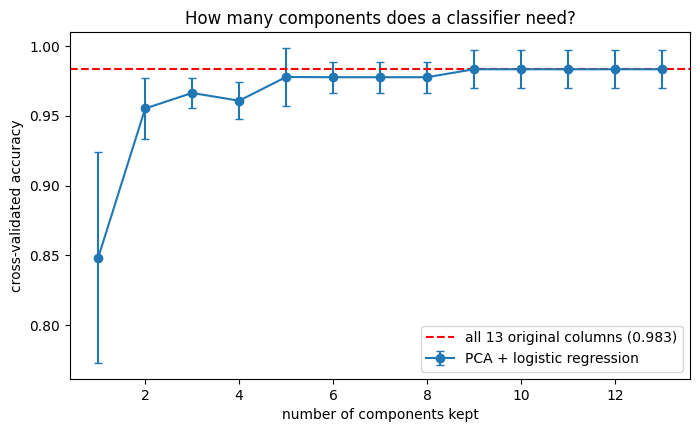

 components  mean accuracy   std
          1          0.848 0.075
          2          0.955 0.022
          3          0.966 0.011
          4          0.961 0.013
          5          0.978 0.021
          6          0.978 0.011
          7          0.978 0.011
          8          0.978 0.011
          9          0.983 0.014
         10          0.983 0.014
         11          0.983 0.014
         12          0.983 0.014
         13          0.983 0.014

All 13 original columns: accuracy 0.983


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for n in range(1, 14):
    model = make_pipeline(StandardScaler(), PCA(n_components=n), LogisticRegression(max_iter=2000))
    s = cross_val_score(model, X, y, cv=cv)
    rows.append({'components': n, 'mean accuracy': s.mean(), 'std': s.std()})
res = pd.DataFrame(rows)

all_cols = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, y, cv=cv)

plt.figure(figsize=(8, 4.5))
plt.errorbar(res['components'], res['mean accuracy'], yerr=res['std'], marker='o', capsize=3, label='PCA + logistic regression')
plt.axhline(all_cols.mean(), color='red', linestyle='--', label=f'all 13 original columns ({all_cols.mean():.3f})')
plt.xlabel('number of components kept')
plt.ylabel('cross-validated accuracy')
plt.title('How many components does a classifier need?')
plt.legend()
plt.show()

print(res.round(3).to_string(index=False))
print()
print('All 13 original columns: accuracy', round(all_cols.mean(), 3))

**How to read this:** with only 1 component the accuracy is clearly lower (about 85% in a real run), but it climbs fast: 2 components already give about 95% and 5 components about 98%, **close to the 98% that all 13 columns give**. So we can shrink the data a lot with little loss. The error bars show that on a data set this small (178 wines) differences of a percentage point are within the noise, so do not over-interpret them. In real projects, PCA is mostly useful when you have **many more** columns or very correlated ones; for a model that already works well with few columns it often brings little.

## Step 9: Reconstruction and odd wines

PCA is lossy compression: if we keep `n` components and **rebuild** the 13 columns from them, we get an approximation. The **reconstruction error** tells how much information was thrown away.

It also gives us a trick: wines that are **badly reconstructed** by the first 2 components do not follow the main patterns, so they can be considered **unusual wines** (outliers).

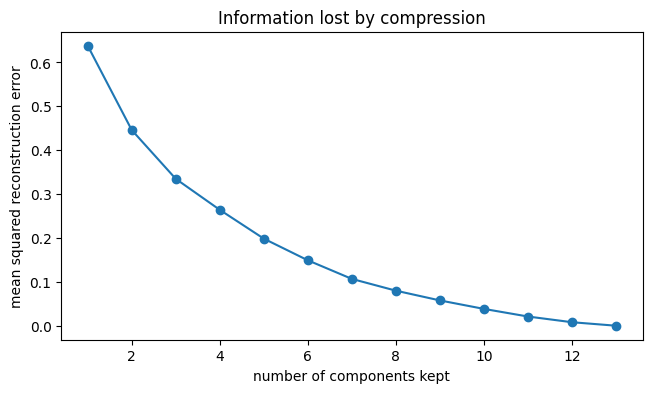

 components  reconstruction error (MSE)
          1                       0.638
          2                       0.446
          3                       0.335
          4                       0.264
          5                       0.198
          6                       0.149

The 5 wines that the 2-component map describes worst:
 wine (row)  reconstruction error  cultivar
        121                 36.18         1
         95                 25.29         1
         69                 24.98         1
         59                 24.01         1
        110                 22.98         1
(the typical wine has an error of about 4.1)


In [9]:
rows = []
for n in range(1, 14):
    p = PCA(n_components=n).fit(Xs)
    rebuilt = p.inverse_transform(p.transform(Xs))
    rows.append({'components': n, 'reconstruction error (MSE)': ((Xs - rebuilt) ** 2).mean()})
rec = pd.DataFrame(rows)

plt.figure(figsize=(7.5, 4))
plt.plot(rec['components'], rec['reconstruction error (MSE)'], marker='o')
plt.xlabel('number of components kept')
plt.ylabel('mean squared reconstruction error')
plt.title('Information lost by compression')
plt.show()
print(rec.round(3).head(6).to_string(index=False))

# odd wines: the biggest errors when only 2 components are used
p2 = PCA(n_components=2).fit(Xs)
err = ((Xs - p2.inverse_transform(p2.transform(Xs))) ** 2).sum(axis=1)
odd = pd.DataFrame({'wine (row)': np.arange(len(X)), 'reconstruction error': err, 'cultivar': y}).sort_values('reconstruction error', ascending=False)
print()
print('The 5 wines that the 2-component map describes worst:')
print(odd.head(5).round(2).to_string(index=False))
print(f'(the typical wine has an error of about {np.median(err):.1f})')

**What to notice:** the error shrinks as we add components and reaches zero with all 13 (nothing is lost). In a real run, the five worst-described wines all belong to the same cultivar (1), which is the most varied group. The "odd wines" list is a simple **anomaly detector**: those wines have properties the first two components cannot express. They are worth a second look (a measurement error, or a really unusual wine).

## Step 10: PCA before clustering

Because PCA is unsupervised, we can test it with K-Means from your last project. We cluster the wines into 3 groups in two ways: on all 13 scaled columns, and on the first 2 components. Then we check, with the **Adjusted Rand Index (ARI)**, how well each grouping matches the real cultivars (1.0 is a perfect match, 0 is random). The cultivars were never used for the clustering.

           K-Means on  ARI vs real cultivars  silhouette
all 13 scaled columns                  0.897       0.285
   first 2 components                  0.895       0.561


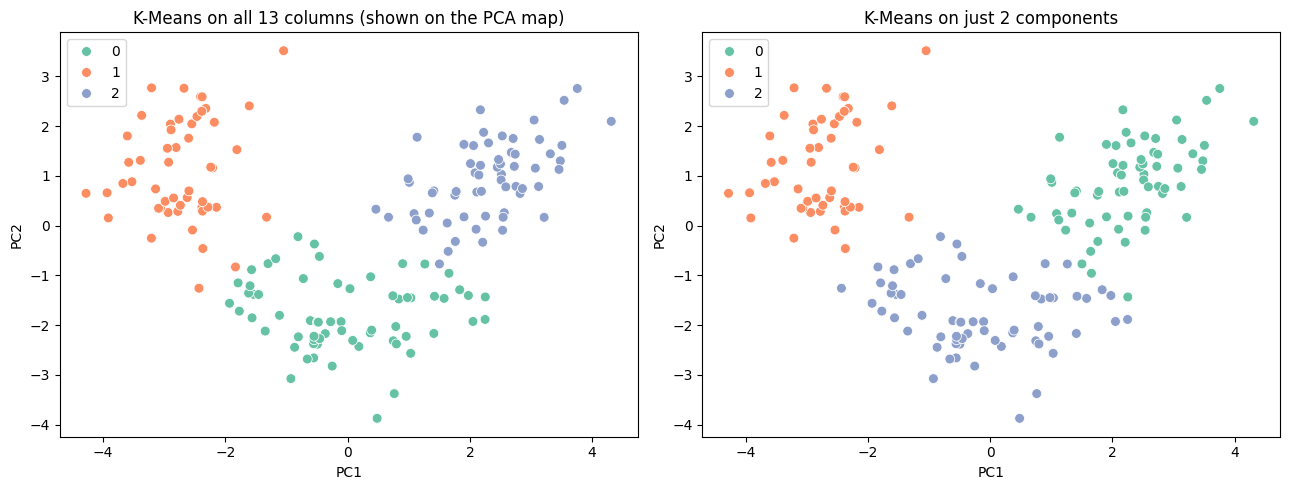

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

km_all = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xs)
km_pca = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)

print(pd.DataFrame([
    {'K-Means on': 'all 13 scaled columns', 'ARI vs real cultivars': adjusted_rand_score(y, km_all.labels_),
     'silhouette': silhouette_score(Xs, km_all.labels_)},
    {'K-Means on': 'first 2 components', 'ARI vs real cultivars': adjusted_rand_score(y, km_pca.labels_),
     'silhouette': silhouette_score(Z, km_pca.labels_)},
]).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km_all.labels_, palette='Set2', s=50, ax=axes[0])
axes[0].set_title('K-Means on all 13 columns (shown on the PCA map)')
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km_pca.labels_, palette='Set2', s=50, ax=axes[1])
axes[1].set_title('K-Means on just 2 components')
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

**What to notice:** both clusterings recover the real cultivars well, even though the algorithm never saw the labels. The grouping on 2 components is about as good as the one on all 13 columns, and much easier to **draw and explain**. (The silhouette scores are not directly comparable, because they are measured in different spaces.) Remember that the colours of the clusters are arbitrary: "cluster 0" does not have to be "cultivar 0".

## Step 11: Transform a new wine

To place a **new** wine on the map we must apply the **same scaler and the same PCA** that were learned from the training wines (never refit them on the new wine).

The new wine lands at PC1 = 1.12, PC2 = 0.00
Distance to the centre of each cultivar on the map:
cultivar
0    1.51
1    2.02
2    4.07
Closest cultivar: 0


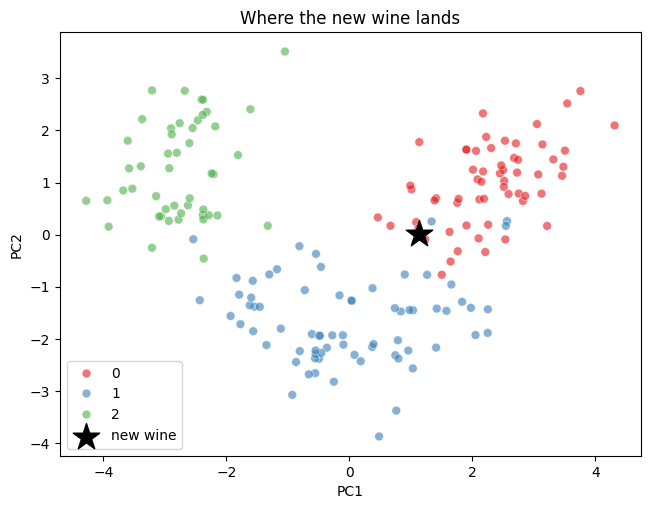

In [11]:
final_pipe = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(X)

new_wine = X.median().to_frame().T            # start from a typical wine ...
new_wine['flavanoids'] = 3.2                  # ... and make it rich in flavanoids,
new_wine['proline'] = 1100                    # high in proline
new_wine['color_intensity'] = 4.0

coords = final_pipe.transform(new_wine)[0]
print(f'The new wine lands at PC1 = {coords[0]:.2f}, PC2 = {coords[1]:.2f}')

# which cultivar is its closest neighbour on the map?
centres = pd.DataFrame(final_pipe.transform(X)).groupby(y.values).mean()
dist = ((centres - coords) ** 2).sum(axis=1) ** 0.5
print('Distance to the centre of each cultivar on the map:')
print(dist.round(2).rename_axis('cultivar').to_string())
print('Closest cultivar:', int(dist.idxmin()))

plt.figure(figsize=(7.5, 5.5))
Zall = final_pipe.transform(X)
sns.scatterplot(x=Zall[:, 0], y=Zall[:, 1], hue=y, palette='Set1', s=40, alpha=0.6)
plt.scatter(coords[0], coords[1], marker='*', s=400, color='black', label='new wine')
plt.legend()
plt.title('Where the new wine lands')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

**Try it:** change the three values and see how the star moves across the map. Note that the new wine is placed using only the **training** statistics, which is exactly what you would do for any new data.

## Bonus: save the data as a CSV file

If you want a CSV file of this data set (13 measurement columns plus `cultivar`), run this cell. In Colab it also downloads the file.

In [12]:
df.to_csv('wine_cultivars.csv', index=False)
print('Saved wine_cultivars.csv with', df.shape[0], 'rows and', df.shape[1], 'columns')

try:
    from google.colab import files
    files.download('wine_cultivars.csv')
except ImportError:
    print('(Not running in Colab: the file was saved in the current folder.)')

Saved wine_cultivars.csv with 178 rows and 14 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Things to remember about PCA

- **Always scale first**, unless your columns already share units and scale.
- Fit the scaler and PCA on the **training data only**, then apply them to new data (use a pipeline).
- PCA is **linear**: it finds straight-line directions. For curved structures, try **t-SNE** or **UMAP** (good for pictures, not for modelling).
- More variance does not always mean more **useful** information for your prediction task.
- The components are mixtures of columns, so they are harder to explain than the original columns. If you must explain a model to others, think twice before using PCA.

## Practice ideas

1. Go back to the digits data (`load_digits`) and use PCA to plot the 10 digits in 2D. How well do they separate?
2. Use PCA with `n_components=0.95` (a float means "keep 95% of the variance") and see how many components you get.
3. Add `whiten=True` to PCA and see what changes in the plots and in the classifier.
4. Use `KernelPCA` with an RBF kernel and compare the map with the linear one.
5. Compress a photo: treat each row of pixels as a data point, apply PCA, and rebuild the image from 5, 20 and 50 components.
6. Try `TruncatedSVD` (a cousin of PCA used on sparse data such as text) on the SMS spam data.